# Binary Skin Cancer Classification (Benign vs Malignant) - EfficientNetV2-S (timm)


## 0) Install dependencies (run once)

In [ ]:

!pip -q install timm scikit-learn pillow tqdm


## 1) Imports, device, reproducibility

In [1]:

import os, random
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, Tuple

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset, WeightedRandomSampler

import timm
from torchvision import transforms
from torchvision.datasets import ImageFolder

from tqdm import tqdm

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, auc,
    precision_recall_curve, average_precision_score,
    f1_score, precision_score, recall_score
)

import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    torch.backends.cudnn.benchmark = True

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(42)

import pandas as pd

from PIL import Image

from torch.utils.data import Dataset


Device: cuda
GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU


## 2) Config

In [9]:
@dataclass
class CFG:
    # ---- DATA ----
    DATA_DIR: str = r"data\Skin Lesions Classification"
    TRAIN_SUBDIR: str = "train"
    TEST_SUBDIR: str = "test"
    VAL_SPLIT: float = 0.2

    # ---- MODEL ----
    MODEL_NAME: str = "tf_efficientnetv2_s.in21k_ft_in1k"
    IMG_SIZE: int = 224

    # ---- TRAINING ----
    EPOCHS: int = 50
    BATCH_SIZE: int = 16        # for 4GB VRAM you may need 8 or 16
    LR: float = 3e-4
    WEIGHT_DECAY: float = 0.02
    NUM_WORKERS: int = 0        # keep 0 on Windows + Jupyter stability

    # ---- IMBALANCE ----
    USE_WEIGHTED_SAMPLER: bool = True
    LABEL_SMOOTHING: float = 0.05

    # ---- AMP ----
    USE_AMP: bool = True

cfg = CFG()
print(cfg)

TRAIN_DIR = os.path.join(cfg.DATA_DIR, cfg.TRAIN_SUBDIR)
TEST_DIR  = os.path.join(cfg.DATA_DIR, cfg.TEST_SUBDIR)
print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR :", TEST_DIR)


CFG(DATA_DIR='data\\Skin Lesions Classification', TRAIN_SUBDIR='train', TEST_SUBDIR='test', VAL_SPLIT=0.2, MODEL_NAME='tf_efficientnetv2_s.in21k_ft_in1k', IMG_SIZE=224, EPOCHS=50, BATCH_SIZE=16, LR=0.0003, WEIGHT_DECAY=0.02, NUM_WORKERS=0, USE_WEIGHTED_SAMPLER=True, LABEL_SMOOTHING=0.05, USE_AMP=True)
TRAIN_DIR: data\Skin Lesions Classification\train
TEST_DIR : data\Skin Lesions Classification\test


## 3) Transforms

In [10]:

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

train_tfms = transforms.Compose([
    transforms.RandomResizedCrop(cfg.IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.05),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_tfms = transforms.Compose([
    transforms.Resize((cfg.IMG_SIZE, cfg.IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


## 4) Load datasets + stratified train/val split


In [11]:
full_train = ImageFolder(TRAIN_DIR, transform=train_tfms)
class_names = full_train.classes
print("Classes:", class_names)

y = np.array(full_train.targets)

splitter = StratifiedShuffleSplit(n_splits=1, test_size=cfg.VAL_SPLIT, random_state=42)
train_idx, val_idx = next(splitter.split(np.zeros(len(y)), y))

train_ds = Subset(full_train, train_idx)

val_base = ImageFolder(TRAIN_DIR, transform=eval_tfms)
val_ds = Subset(val_base, val_idx)

test_ds = ImageFolder(TEST_DIR, transform=eval_tfms)

print("Train size:", len(train_ds))
print("Val size  :", len(val_ds))
print("Test size :", len(test_ds))

def subset_targets(subset: Subset, base: ImageFolder):
    return np.array([base.targets[i] for i in subset.indices])

train_targets = subset_targets(train_ds, full_train)
val_targets   = subset_targets(val_ds, val_base)
test_targets  = np.array(test_ds.targets)

for name, arr in [("train", train_targets), ("val", val_targets), ("test", test_targets)]:
    counts = {class_names[i]: int((arr==i).sum()) for i in range(len(class_names))}
    print(name, counts)


Classes: ['benign', 'malignant']
Train size: 2109
Val size  : 528
Test size : 661
train {'benign': 1152, 'malignant': 957}
val {'benign': 288, 'malignant': 240}
test {'benign': 361, 'malignant': 300}


## 5) DataLoaders (with optional WeightedRandomSampler)

In [12]:

def make_loader(dataset, batch_size, shuffle=False, sampler=None):
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle if sampler is None else False,
        sampler=sampler,
        num_workers=cfg.NUM_WORKERS,
        pin_memory=(device.type=="cuda"),
        drop_last=False
    )

sampler = None
if cfg.USE_WEIGHTED_SAMPLER:
    counts = np.bincount(train_targets, minlength=len(class_names)).astype(np.float32)
    class_w = 1.0 / np.maximum(counts, 1.0)
    sample_w = class_w[train_targets]
    sampler = WeightedRandomSampler(weights=sample_w, num_samples=len(sample_w), replacement=True)
    print("Using WeightedRandomSampler. class_counts:", counts)

train_loader = make_loader(train_ds, cfg.BATCH_SIZE, shuffle=True, sampler=sampler)
val_loader   = make_loader(val_ds, cfg.BATCH_SIZE, shuffle=False)
test_loader  = make_loader(test_ds, cfg.BATCH_SIZE, shuffle=False)


Using WeightedRandomSampler. class_counts: [1152.  957.]


## 6) Build model (ConvNeXt / EfficientNetV2 via timm)

In [13]:

num_classes = len(class_names)
assert num_classes == 2, f"Expected 2 classes, found {num_classes}. Check folder names."

model = timm.create_model(cfg.MODEL_NAME, pretrained=True, num_classes=num_classes).to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=cfg.LABEL_SMOOTHING)
optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.LR, weight_decay=cfg.WEIGHT_DECAY)

steps_per_epoch = len(train_loader)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=cfg.LR,
    epochs=cfg.EPOCHS,
    steps_per_epoch=steps_per_epoch
)

scaler = torch.cuda.amp.GradScaler(enabled=(cfg.USE_AMP and device.type=="cuda"))

print("Model:", cfg.MODEL_NAME)
print("Params (M):", sum(p.numel() for p in model.parameters())/1e6)


Model: tf_efficientnetv2_s.in21k_ft_in1k
Params (M): 20.18005


C:\Users\rupes\AppData\Local\Temp\ipykernel_15052\2430738697.py:17: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(cfg.USE_AMP and device.type=="cuda"))


## 7) Training + evaluation utilities

In [14]:

@torch.no_grad()
def predict_probs(loader):
    model.eval()
    all_probs, all_y = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        with torch.amp.autocast(device_type=device.type, enabled=(cfg.USE_AMP and device.type == 'cuda')):
            logits = model(x)
            probs = torch.softmax(logits, dim=1)
        all_probs.append(probs.detach().cpu().numpy())
        all_y.append(y.detach().cpu().numpy())
    return np.concatenate(all_probs, axis=0), np.concatenate(all_y, axis=0)

@torch.no_grad()
def evaluate(loader, threshold=0.5):
    probs, y_true = predict_probs(loader)
    pos_idx = 1  # positive class assumed to be index 1
    y_prob_pos = probs[:, pos_idx]
    y_pred_thr = (y_prob_pos >= threshold).astype(int)
    y_pred_arg = probs.argmax(axis=1)

    acc = accuracy_score(y_true, y_pred_arg)
    bacc = balanced_accuracy_score(y_true, y_pred_arg)
    f1 = f1_score(y_true, y_pred_thr)
    prec = precision_score(y_true, y_pred_thr, zero_division=0)
    rec = recall_score(y_true, y_pred_thr, zero_division=0)

    try:
        roc_auc = roc_auc_score(y_true, y_prob_pos)
    except Exception:
        roc_auc = float('nan')
    try:
        ap = average_precision_score(y_true, y_prob_pos)
    except Exception:
        ap = float('nan')

    return {
        "top1_acc": acc,
        "balanced_acc": bacc,
        "f1@0.5": f1,
        "precision@0.5": prec,
        "recall@0.5": rec,
        "roc_auc": roc_auc,
        "pr_auc": ap
    }

@torch.no_grad()
def evaluate_loss_and_acc(loader):
    model.eval()
    running_loss = 0.0
    running_correct = 0
    total = 0

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        with torch.amp.autocast(device_type=device.type, enabled=(cfg.USE_AMP and device.type == 'cuda')):
            logits = model(x)
            loss = criterion(logits, y)

        running_loss += loss.item() * x.size(0)
        preds = torch.argmax(logits, dim=1)
        running_correct += (preds == y).sum().item()
        total += y.size(0)

    return running_loss / max(total, 1), running_correct / max(total, 1)

def train_one_epoch(epoch: int):
    model.train()
    running_loss = 0.0
    running_correct = 0
    total = 0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{cfg.EPOCHS}", leave=False)
    for x, y in pbar:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type=device.type, enabled=(cfg.USE_AMP and device.type == 'cuda')):
            logits = model(x)
            loss = criterion(logits, y)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        running_loss += loss.item() * x.size(0)
        preds = torch.argmax(logits, dim=1)
        running_correct += (preds == y).sum().item()
        total += y.size(0)

        pbar.set_postfix({"loss": float(loss.item()), "lr": float(scheduler.get_last_lr()[0])})

    return running_loss / max(total, 1), running_correct / max(total, 1)


## 8) Train loop (save best by validation F1@0.5)

In [15]:

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_top1": [],
    "val_f1": [],
    "val_auc": []
}
best_f1 = -1.0
best_path = f"best_{cfg.MODEL_NAME.replace('.', '_')}.pt"

for epoch in range(cfg.EPOCHS):
    train_loss, train_acc = train_one_epoch(epoch)
    val_loss, val_top1 = evaluate_loss_and_acc(val_loader)
    val_metrics = evaluate(val_loader, threshold=0.5)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_top1"].append(val_top1)
    history["val_f1"].append(val_metrics["f1@0.5"])
    history["val_auc"].append(val_metrics["roc_auc"])

    print(
        f"[Epoch {epoch+1:02d}] "
        f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
        f"val_loss={val_loss:.4f} val_top1={val_top1:.4f} "
        f"val_f1@0.5={val_metrics['f1@0.5']:.4f} val_auc={val_metrics['roc_auc']:.4f}"
    )

    if val_metrics["f1@0.5"] > best_f1:
        best_f1 = val_metrics["f1@0.5"]
        torch.save(model.state_dict(), best_path)
        print("  ? saved best:", best_path)

print("Best val F1@0.5:", best_f1, "checkpoint:", best_path)


Epoch 1/50:   0%|          | 0/132 [00:00<?, ?it/s]d:\Projects\environments\pytorch-env\Lib\site-packages\torch\optim\lr_scheduler.py:227: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(


[Epoch 01] train_loss=4.7044 train_acc=0.6766 | val_loss=2.6026 val_top1=0.7727 val_f1@0.5=0.7842 val_auc=0.8708
  ? saved best: best_tf_efficientnetv2_s_in21k_ft_in1k.pt


[Epoch 02] train_loss=1.9460 train_acc=0.7805 | val_loss=1.6291 val_top1=0.8201 val_f1@0.5=0.8017 val_auc=0.8771
  ? saved best: best_tf_efficientnetv2_s_in21k_ft_in1k.pt


[Epoch 03] train_loss=1.4232 train_acc=0.8080 | val_loss=1.4360 val_top1=0.8239 val_f1@0.5=0.7947 val_auc=0.8849


[Epoch 04] train_loss=1.1827 train_acc=0.8108 | val_loss=1.2491 val_top1=0.8011 val_f1@0.5=0.7586 val_auc=0.8916


[Epoch 05] train_loss=0.8236 train_acc=0.8364 | val_loss=1.1264 val_top1=0.8277 val_f1@0.5=0.7828 val_auc=0.9160


... (41 outputs left out)

[Epoch 47] train_loss=0.1333 train_acc=0.9953 | val_loss=0.3104 val_top1=0.8977 val_f1@0.5=0.8866 val_auc=0.9657


[Epoch 48] train_loss=0.1301 train_acc=0.9991 | val_loss=0.3119 val_top1=0.9034 val_f1@0.5=0.8931 val_auc=0.9654


[Epoch 49] train_loss=0.1312 train_acc=0.9976 | val_loss=0.3135 val_top1=0.9053 val_f1@0.5=0.8936 val_auc=0.9655


[Epoch 50] train_loss=0.1303 train_acc=0.9991 | val_loss=0.3177 val_top1=0.8977 val_f1@0.5=0.8870 val_auc=0.9631
Best val F1@0.5: 0.9010526315789473 checkpoint: best_tf_efficientnetv2_s_in21k_ft_in1k.pt


## 9) Plot learning curves

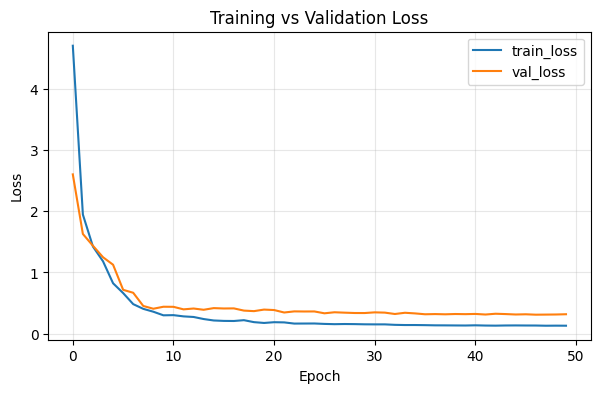

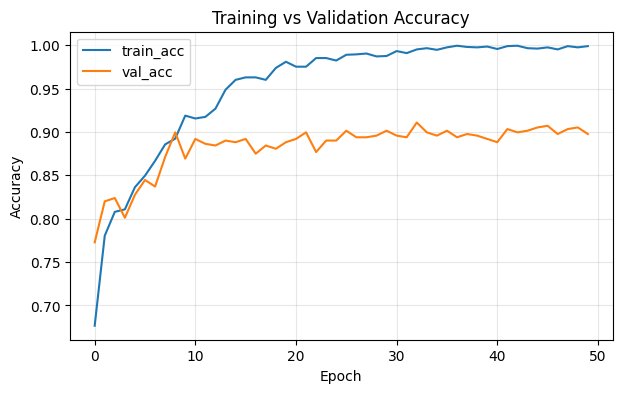

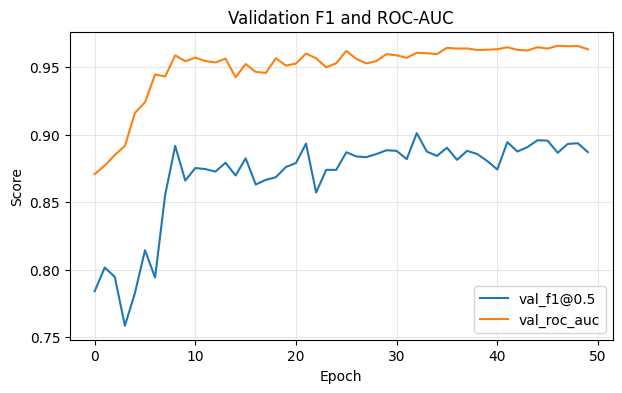

In [16]:

plt.figure(figsize=(7, 4))
plt.plot(history["train_loss"], label="train_loss")
plt.plot(history["val_loss"], label="val_loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history["train_acc"], label="train_acc")
plt.plot(history["val_top1"], label="val_acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history["val_f1"], label="val_f1@0.5")
plt.plot(history["val_auc"], label="val_roc_auc")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation F1 and ROC-AUC")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 10) Final evaluation on test set + reports + plots

TEST metrics: {'top1_acc': 0.9152798789712556, 'balanced_acc': 0.9145521698984302, 'f1@0.5': 0.9066666666666666, 'precision@0.5': 0.9066666666666666, 'recall@0.5': 0.9066666666666666, 'roc_auc': 0.9639427516158818, 'pr_auc': 0.9556282055913234}

Classification report (argmax):
              precision    recall  f1-score   support

      benign       0.92      0.92      0.92       361
   malignant       0.91      0.91      0.91       300

    accuracy                           0.92       661
   macro avg       0.91      0.91      0.91       661
weighted avg       0.92      0.92      0.92       661



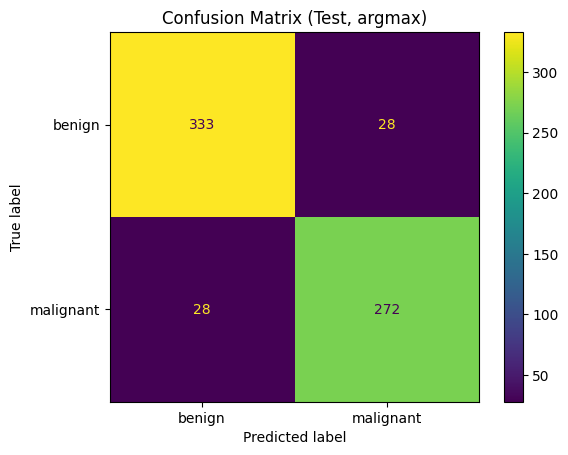

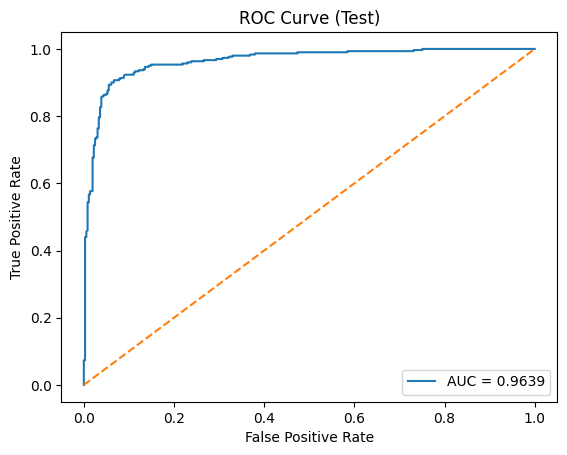

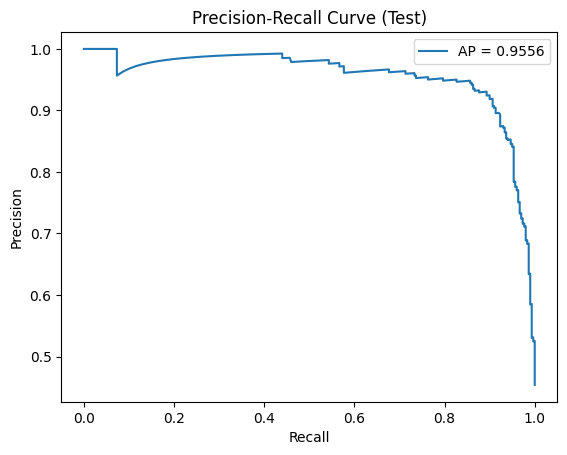

In [17]:

model.load_state_dict(torch.load(best_path, map_location=device))

test_metrics = evaluate(test_loader, threshold=0.5)
print("TEST metrics:", test_metrics)

probs, y_true = predict_probs(test_loader)
y_pred_argmax = probs.argmax(axis=1)

print("\nClassification report (argmax):")
print(classification_report(y_true, y_pred_argmax, target_names=class_names, zero_division=0))

cm = confusion_matrix(y_true, y_pred_argmax)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(values_format="d")
plt.title("Confusion Matrix (Test, argmax)")
plt.show()

pos_idx = 1
y_prob_pos = probs[:, pos_idx]

fpr, tpr, _ = roc_curve(y_true, y_prob_pos)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
plt.plot([0,1],[0,1],"--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (Test)")
plt.legend()
plt.show()

prec, rec, _ = precision_recall_curve(y_true, y_prob_pos)
ap = average_precision_score(y_true, y_prob_pos)

plt.figure()
plt.plot(rec, prec, label=f"AP = {ap:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve (Test)")
plt.legend()
plt.show()
